<div class="alert alert-info">
<h1>Logistics Regression</h1>
<h4>Environmental Statistics 3</h4>
C.F. Dormann
</div>

There is one thing to learn today:
  -  Moving back and forth between the response and the link scale for Bernoulli and binomial data.

# 1.0   Exercise 1: Bernoulli = logistic regression
In the 1996 presidential elections in the USA, Bill Clinton ran against Bob Dole. Here are the results of a poll, along with a range of predictors.

### 1.1    Load the data and look at the *summary* of it.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.mosaicplot import mosaic
from statsmodels.stats.anova import anova_lm
from statsmodels.formula.api import ols
import statsmodels.api as sm
from patsy import dmatrices
import patsy
from scipy import stats
from tabulate import tabulate

import warnings
warnings.filterwarnings('ignore')

nes96 = pd.read_csv("nes96.csv")
nes96.head(7)

,popul,TVnews,selfLR,ClinLR,DoleLR,PID,age,educ,income,vote
0,0,7,extCon,extLib,Con,strRep,36,HS,$3Kminus,Dole
1,190,1,sliLib,sliLib,sliCon,weakDem,20,Coll,$3Kminus,Clinton
2,31,7,Lib,Lib,Con,weakDem,24,BAdeg,$3Kminus,Clinton
3,83,4,sliLib,Mod,sliCon,weakDem,28,BAdeg,$3Kminus,Clinton
4,640,7,sliCon,Con,Mod,strDem,68,BAdeg,$3Kminus,Clinton
5,110,3,sliLib,Mod,Con,weakDem,21,Coll,$3Kminus,Clinton
6,100,7,sliCon,Con,Mod,weakDem,77,Coll,$3Kminus,Clinton


In [3]:
nes96.describe()

,popul,TVnews,age
count,944.000000,944.000000,944.000000
mean,306.381356,3.727754,47.043432
std,1082.606745,2.677235,16.423130
min,0.000000,0.000000,19.000000
25%,1.000000,1.000000,34.000000
50%,22.000000,3.000000,44.000000
75%,110.000000,7.000000,58.000000
max,7300.000000,7.000000,91.000000


In [4]:
nes96.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 944 entries, 0 to 943
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   popul   944 non-null    int64 
 1   TVnews  944 non-null    int64 
 2   selfLR  944 non-null    object
 3   ClinLR  944 non-null    object
 4   DoleLR  944 non-null    object
 5   PID     944 non-null    object
 6   age     944 non-null    int64 
 7   educ    944 non-null    object
 8   income  944 non-null    object
 9   vote    944 non-null    object
dtypes: int64(3), object(7)
memory usage: 73.9+ KB


### 1.2    Plot vote as a function of population density
Maybe use some transformation of the x-axis to get this more evenly spaced out. Note: if your transformation throws a warning, check that it can be applied to all values in `popul`. That was the point of the `summary` statement before!

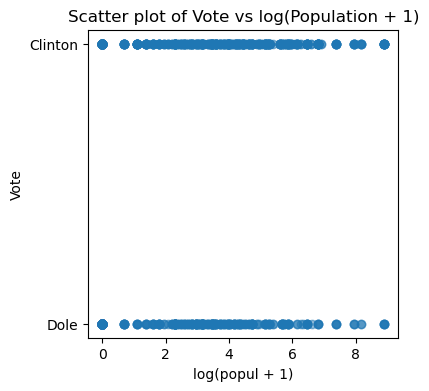

In [5]:
# SCATTER PLOT (Wrong way to visualise categorical variables)

# Log-transform 'popul' + 1 for the plot
nes96['log_popul_plus1'] = np.log(nes96['popul'] + 1)

# Plot using matplotlib
plt.figure(figsize=(4, 4))
plt.scatter(nes96['log_popul_plus1'], nes96['vote'], alpha=0.5)
plt.xlabel('log(popul + 1)')
plt.ylabel('Vote')
plt.title('Scatter plot of Vote vs log(Population + 1)')
plt.show()

Of course, scatter plot is not the best plot for a binary response.

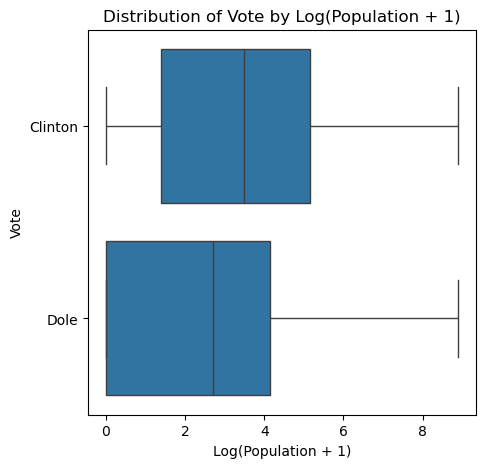

In [6]:
# BOXPLOT

# Convert 'vote' to categorical for Boxplot
nes96['vote'] = nes96['vote'].astype('category')

# Create the boxplot
plt.figure(figsize=(5, 5))
sns.boxplot(x='log_popul_plus1', y='vote', data=nes96)
plt.xlabel('Log(Population + 1)')
plt.ylabel('Vote')
plt.title('Distribution of Vote by Log(Population + 1)')
plt.show()

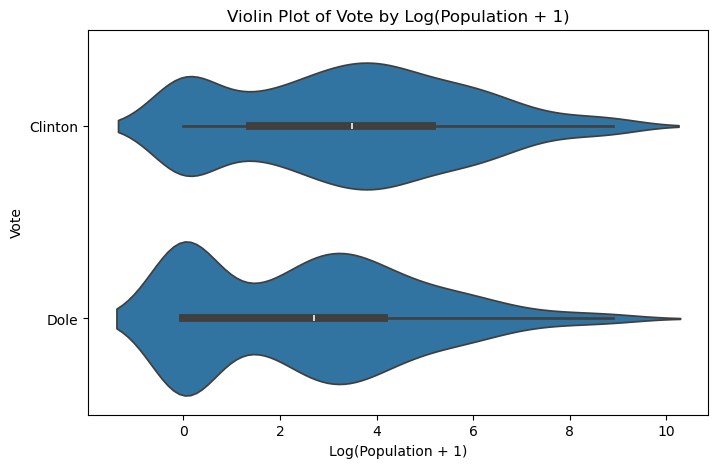

In [7]:
# VIOLIN PLOT

plt.figure(figsize=(8, 5))
sns.violinplot(x='log_popul_plus1', y='vote', data=nes96)
plt.xlabel('Log(Population + 1)')
plt.ylabel('Vote')
plt.title('Violin Plot of Vote by Log(Population + 1)')
plt.show()


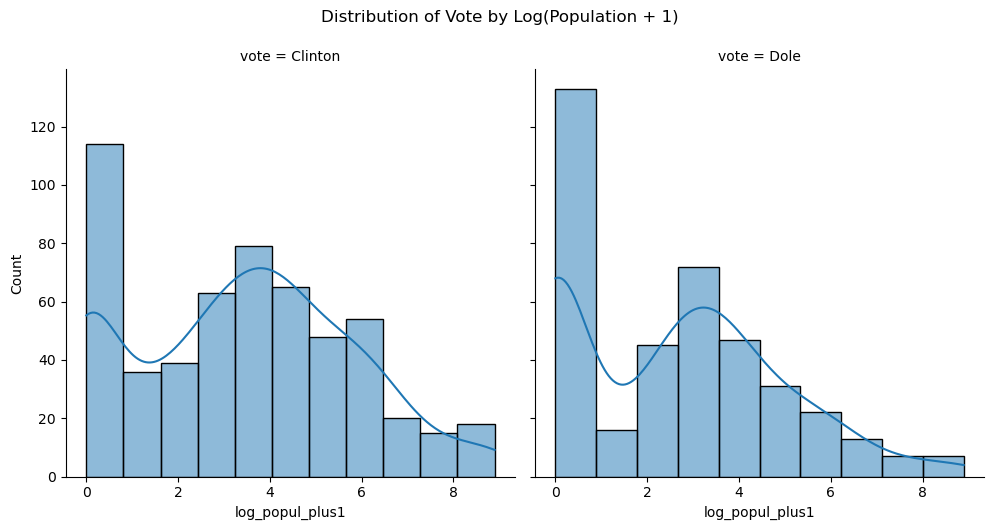

In [8]:
# FACET HISTOGRAM

g = sns.FacetGrid(nes96, col='vote', height=5)
g.map(sns.histplot, 'log_popul_plus1', kde=True)
g.add_legend()
plt.suptitle('Distribution of Vote by Log(Population + 1)', y=1.05)
plt.show()

<Figure size 1000x600 with 0 Axes>

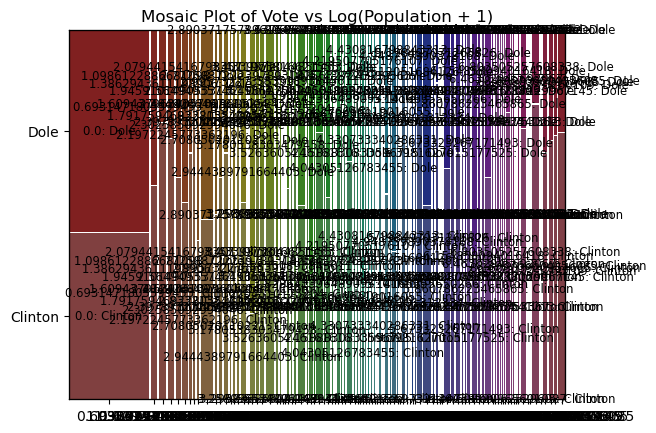

In [9]:
# MOSIAC PLOT (without bins)


# Create a contingency table
contingency_table = pd.crosstab(nes96['log_popul_plus1'], nes96['vote'])

# Create a mosaic plot
plt.figure(figsize=(10, 6))
mosaic(contingency_table.stack(), title='Mosaic Plot of Vote vs Log(Population + 1)', 
       labelizer=lambda k: f'{k[0]}: {k[1]}')

plt.show()

<Figure size 600x600 with 0 Axes>

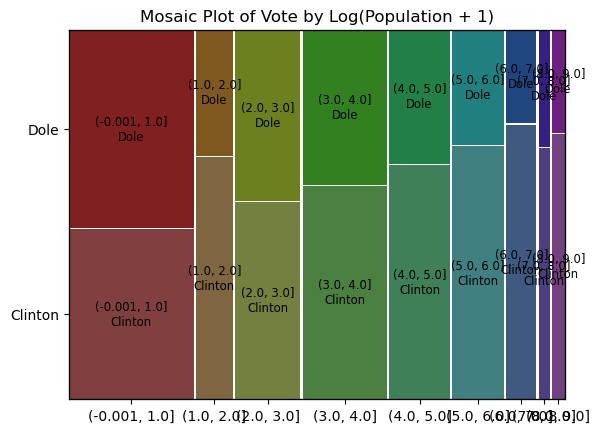

In [10]:
# MOSAIC PLOT (with Bins)
nes96['log_popul'] = np.log(nes96['popul'] + 1)


# Create bins for log_popul_plus1
bins = np.arange(0, nes96['log_popul'].max() + 1 , 1)

# Cut the log_popul_plus1 into bins
nes96['log_popul_bin'] = pd.cut(nes96['log_popul_plus1'], bins=bins, include_lowest=True)

# Create a contingency table
contingency_table = pd.crosstab(nes96['log_popul_bin'], nes96['vote'])

# Create a mosaic plot
plt.figure(figsize=(6, 6))
mosaic(contingency_table.stack(), title='Mosaic Plot of Vote by Log(Population + 1)')

plt.show()

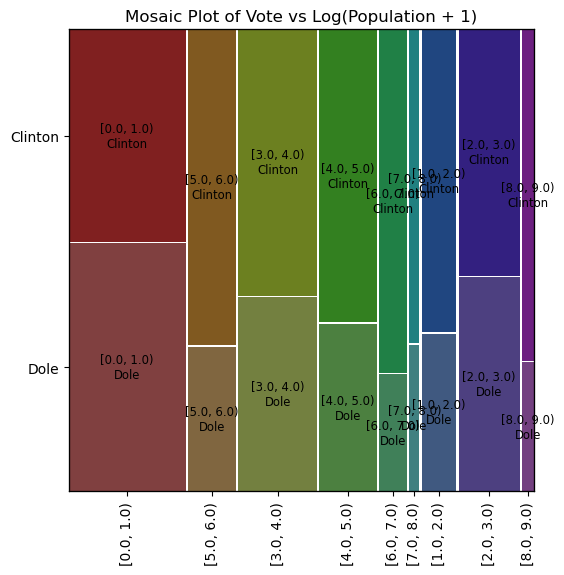

In [11]:
# MOSAIC PLOT with Bins (simplified)


nes96['log_popul'] = np.log(nes96['popul'] + 1)

# Create the mosaic plot
fig, ax = plt.subplots(figsize=(6, 6))
bins = np.arange(0, nes96['log_popul'].max() + 1 , 1)
nes96['log_popul_grp'] = pd.cut(nes96['log_popul'], bins, right=False)

mosaic(nes96, ['log_popul_grp', 'vote'],  title='Mosaic Plot of Vote vs Log(Population + 1)', ax=ax)

labels = ax.get_xticklabels()
ax.set_xticklabels(labels, rotation=90)

plt.show()


Notice a pattern? Well, may be there is, maybe there isn’t. Let’s find out.

### 1.3    Fit a GLM to represent this relationship
Note that vote is a factor, with two levels: Clinton and Dole, not 0 and 1.

In [274]:
# NOTE: This is fitting Clinton=1 and Dole=0 (A Clinton model)

expr = """vote ~ log_popul"""

y, X = dmatrices(expr, nes96, return_type='dataframe')


# Create and Fit the binomial regression model
fm1 = sm.GLM(y, X, family=sm.families.Binomial()).fit()

# Display the summary of the regression results
print(fm1.summary())


                        Generalized Linear Model Regression Results                        
Dep. Variable:     ['vote[Clinton]', 'vote[Dole]']   No. Observations:                  944
Model:                                         GLM   Df Residuals:                      942
Model Family:                             Binomial   Df Model:                            1
Link Function:                               Logit   Scale:                          1.0000
Method:                                       IRLS   Log-Likelihood:                -627.40
Date:                             Tue, 29 Oct 2024   Deviance:                       1254.8
Time:                                     14:06:27   Pearson chi2:                     944.
No. Iterations:                                  4   Pseudo R-squ. (CS):            0.02849
Covariance Type:                         nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
-

In [275]:
# similarly: This is fitting Clinton=1 and Dole=0 (A Clinton model)

formula = "vote ~ np.log(popul+1)"

# Create and Fit the binomial regression model
fm1b = sm.GLM.from_formula(formula,data=nes96, family=sm.families.Binomial()).fit()

# Display the summary of the regression results
print(fm1b.summary())

                        Generalized Linear Model Regression Results                        
Dep. Variable:     ['vote[Clinton]', 'vote[Dole]']   No. Observations:                  944
Model:                                         GLM   Df Residuals:                      942
Model Family:                             Binomial   Df Model:                            1
Link Function:                               Logit   Scale:                          1.0000
Method:                                       IRLS   Log-Likelihood:                -627.40
Date:                             Tue, 29 Oct 2024   Deviance:                       1254.8
Time:                                     14:06:37   Pearson chi2:                     944.
No. Iterations:                                  4   Pseudo R-squ. (CS):            0.02849
Covariance Type:                         nonrobust                                         
                        coef    std err          z      P>|z|      [0.025      0

In [12]:
# Recode to allow Dole take the value of 1 so that the same results as in R is produced.

nes96['vote_encoded'] = (nes96['vote'] == 'Dole').astype(int)  # 1 if 'Dole', 0 if 'Clinton'
# nes96['vote_encoded'] = nes96['vote'].map({'Dole': 1, 'Clinton': 0}).astype(int)

#NOTE: This is fitting Dole=1 and Clinton=0 (A Dole model)
expr = """vote_encoded ~ log_popul"""

y, X = dmatrices(expr, nes96, return_type='dataframe')


# Create and Fit the binomial regression model
fm2 = sm.GLM(y, X, family=sm.families.Binomial()).fit()

# Display the summary of the regression results
print(fm2.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:           vote_encoded   No. Observations:                  944
Model:                            GLM   Df Residuals:                      942
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -627.40
Date:                Tue, 28 Oct 2025   Deviance:                       1254.8
Time:                        13:14:04   Pearson chi2:                     944.
No. Iterations:                     4   Pseudo R-squ. (CS):            0.02849
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1065      0.108      0.988      0.3

In [13]:
# Mapping votes to integers : (A Dole model)
nes96['vote_encoded'] = nes96['vote'].map({'Dole': 1, 'Clinton': 0}).astype(int)

expr = """vote_encoded ~ log_popul"""

y, X = dmatrices(expr, nes96, return_type='dataframe')


# Create and Fit the binomial regression model
fm2 = sm.GLM(y, X, family=sm.families.Binomial()).fit()

# Display the summary of the regression results
print(fm2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           vote_encoded   No. Observations:                  944
Model:                            GLM   Df Residuals:                      942
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -627.40
Date:                Tue, 28 Oct 2025   Deviance:                       1254.8
Time:                        13:14:27   Pearson chi2:                     944.
No. Iterations:                     4   Pseudo R-squ. (CS):            0.02849
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1065      0.108      0.988      0.3

What does that mean? Is the negative estimate for log(popul+1) consistent with the plot above? <br>

Yes it is: With R the response variable is internally coded as Clinton=0, Dole=1 (in alphabetical sequence). Hence the slope estimate is of the probability of 1 (i.e. voting Dole) as affected by population density. But with Python it is coded as Clinton=1, Dole=0 by default as seen above in the `fm1` result, and this can be encoded again to reproduce the same results as in R as seen in `fm2` result.

### 1.4    Make a proper plot, with regression line and CI
With “proper”, we mean not this mosaic plot above, but one that shows population density on the x-axis, and the positions of the Clinton/Dole votes as ticks on the axis (using rug). <br>

Then add the regression results to the figure.

In [14]:
# convert factor into 0/1, with 1 for Dole:

nes96['Dole'] = nes96['vote'].map({'Dole': 1, 'Clinton': 0})
nes96.head(10)

,popul,TVnews,selfLR,ClinLR,DoleLR,PID,age,educ,income,vote,log_popul_plus1,log_popul,log_popul_bin,log_popul_grp,vote_encoded,Dole
0,0,7,extCon,extLib,Con,strRep,36,HS,$3Kminus,Dole,0.000000,0.000000,"(-0.001, 1.0]","[0.0, 1.0)",1,1
1,190,1,sliLib,sliLib,sliCon,weakDem,20,Coll,$3Kminus,Clinton,5.252273,5.252273,"(5.0, 6.0]","[5.0, 6.0)",0,0
2,31,7,Lib,Lib,Con,weakDem,24,BAdeg,$3Kminus,Clinton,3.465736,3.465736,"(3.0, 4.0]","[3.0, 4.0)",0,0
3,83,4,sliLib,Mod,sliCon,weakDem,28,BAdeg,$3Kminus,Clinton,4.430817,4.430817,"(4.0, 5.0]","[4.0, 5.0)",0,0
4,640,7,sliCon,Con,Mod,strDem,68,BAdeg,$3Kminus,Clinton,6.463029,6.463029,"(6.0, 7.0]","[6.0, 7.0)",0,0
5,110,3,sliLib,Mod,Con,weakDem,21,Coll,$3Kminus,Clinton,4.709530,4.709530,"(4.0, 5.0]","[4.0, 5.0)",0,0
6,100,7,sliCon,Con,Mod,weakDem,77,Coll,$3Kminus,Clinton,4.615121,4.615121,"(4.0, 5.0]","[4.0, 5.0)",0,0
7,31,1,sliCon,Mod,sliCon,indRep,21,Coll,$3Kminus,Clinton,3.465736,3.465736,"(3.0, 4.0]","[3.0, 4.0)",0,0
8,180,7,Mod,Con,sliLib,indind,31,Coll,$3Kminus,Clinton,5.198497,5.198497,"(5.0, 6.0]","[5.0, 6.0)",0,0
9,2800,0,sliLib,sliLib,extCon,strDem,39,HS,$3Kminus,Clinton,7.937732,7.937732,"(7.0, 8.0]","[7.0, 8.0)",0,0


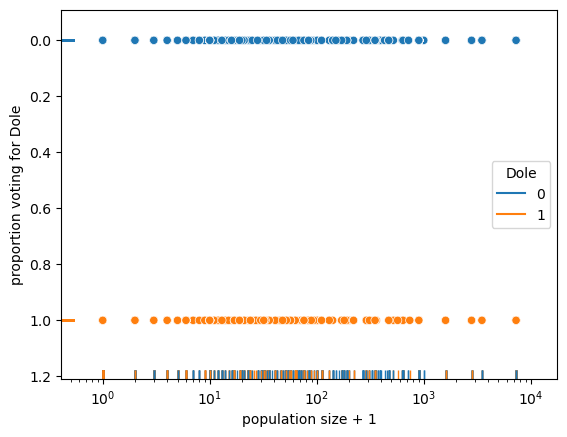

In [15]:
# method1: combine scatterplot and rug plot with seaborn

popul = nes96['popul'] + 1
Dole = nes96['Dole']

sns.scatterplot(data=nes96, x=popul, y=Dole, hue="Dole") 
sns.rugplot(data=nes96, y=Dole, x=popul, hue="Dole")


# Set plot attributes
plt.xscale('log')
plt.xlabel('population size + 1')
plt.ylabel('proportion voting for Dole')
plt.show()

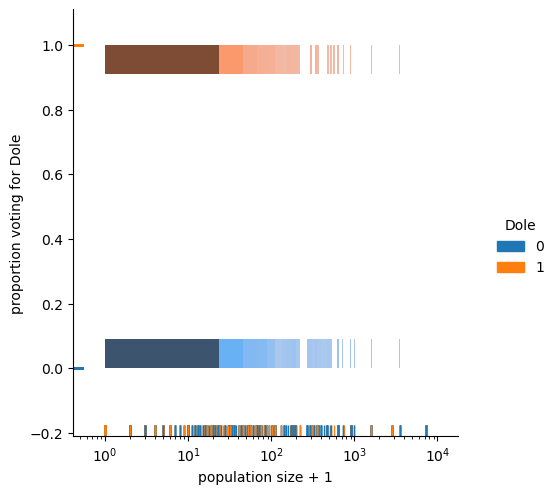

In [16]:
# method2: Use the seaborn Displot with rug=True option
popul = nes96['popul'] + 1
Dole = nes96['Dole'].astype(int)


sns.displot(data=nes96, x=popul, y=Dole, hue="Dole", rug=True)

# Set plot attributes
plt.xscale('log')
plt.xlabel('population size + 1')
plt.ylabel('proportion voting for Dole')
plt.show()



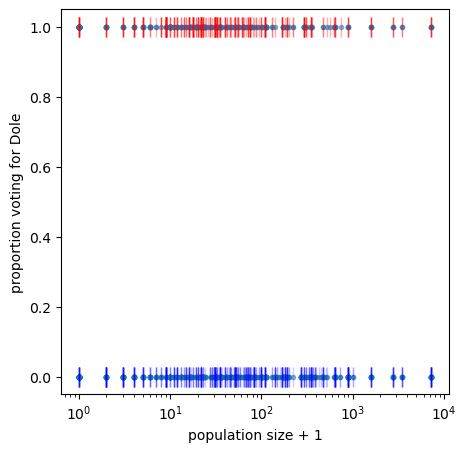

In [17]:
# method3: Create rug plot manually by  with matplotlib line plot

popul = nes96['popul'] + 1
Dole = nes96['Dole']

# Create a scatter plot with log-scaled x-axis
plt.figure(figsize=(5, 5))
plt.scatter(popul, Dole, marker='.', alpha=0.5)

# Create a rug plot

x1 = nes96.loc[nes96['Dole'] == 1, 'popul']
x2 = nes96.loc[nes96['Dole'] == 0, 'popul']

plt.plot(x1, np.ones_like(x1), '|', color='red', markersize=15, alpha=0.3) #top
plt.plot(x2, np.zeros_like(x2), '|', color='blue', markersize=15, alpha=0.2) #bottom


# Set plot attributes
plt.xscale('log')
plt.xlabel('population size + 1')
plt.ylabel('proportion voting for Dole')

plt.show()



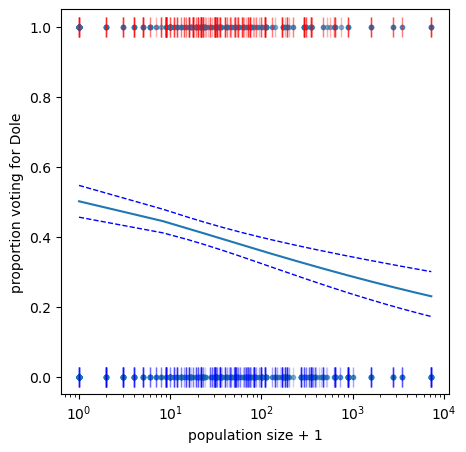

In [18]:
# Now add the regression line with confidence intervals

popul = nes96['popul'] + 1
Dole = nes96['Dole']

# Create a scatter plot with log-scaled x-axis
plt.figure(figsize=(5, 5))
plt.scatter(popul, Dole, marker='.', alpha=0.5)

# Create a rug plot

x1 = nes96.loc[nes96['Dole'] == 1, 'popul']
x2 = nes96.loc[nes96['Dole'] == 0, 'popul']

plt.plot(x1, np.ones_like(x1), '|', color='red', markersize=15, alpha=0.3) #top
plt.plot(x2, np.zeros_like(x2), '|', color='blue', markersize=15, alpha=0.2) #bottom


# make predictions
Pop = list(np.linspace(0, 7300, num=1001) + 1) # as numpy.ndarray
newPop = [round(num, 1) for num in Pop] # rounding to 1 decimal place

Int_ = np.linspace(1.0, 1.0, num=1001) # the intercept as numpy.ndarray

# create the new dataframe for prediction
d = {'Intercept': list(Int_) , 'log_popul': np.log(np.array(newPop) + 1)} 
newPop_df = pd.DataFrame(data=d)     # Convert to a dataframe

# Prediction
preds = fm2.get_prediction(newPop_df).summary_frame(alpha=0.05) # response-type predictions

plt.plot(newPop, preds['mean']) 
plt.plot(newPop, preds['mean_ci_lower'], linestyle='dashed', color = "blue", linewidth=1.0)
plt.plot(newPop, preds['mean_ci_upper'], linestyle='dashed', color = "blue", linewidth=1.0)

# Set plot attributes
plt.xscale('log')
plt.xlabel('population size + 1')
plt.ylabel('proportion voting for Dole')

plt.show()

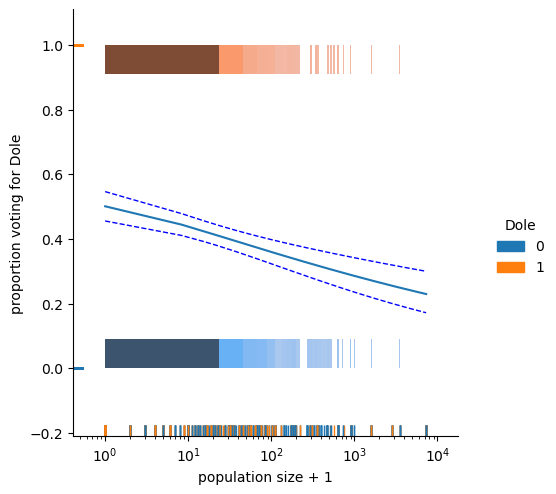

In [19]:
## OR similarly

popul = nes96['popul'] + 1
Dole = nes96['Dole'].astype(int)


sns.displot(data=nes96, x=popul, y=Dole, hue="Dole", rug=True)
# make predictions
Pop = list(np.linspace(0, 7300, num=1001) + 1) # as numpy.ndarray
newPop = [round(num, 1) for num in Pop] # rounding to 1 decimal place

Int_ = np.linspace(1.0, 1.0, num=1001) # the intercept as numpy.ndarray

# create the new dataframe for prediction
d = {'Intercept': list(Int_) , 'log_popul': np.log(np.array(newPop) + 1)} 
newPop_df = pd.DataFrame(data=d)     # Convert to a dataframe

# Prediction
preds = fm2.get_prediction(newPop_df).summary_frame(alpha=0.05) # response-type predictions

plt.plot(newPop, preds['mean']) 
plt.plot(newPop, preds['mean_ci_lower'], linestyle='dashed', color = "blue", linewidth=1.0)
plt.plot(newPop, preds['mean_ci_upper'], linestyle='dashed', color = "blue", linewidth=1.0)

# Set plot attributes
plt.xscale('log')
plt.xlabel('population size + 1')
plt.ylabel('proportion voting for Dole')
plt.show()

The model is not particularly good, and the effect population density not particularly strong, but we can see a (significant) negative effect on voting for Dole, who did not resonate as well with the urban electorate

## 2.0   Exercise 2: Interactions
Let us return again to the Presidential Elections from exercise 1. We now want to investigate the interactive effect of two predictors, population density and level of education. Since level of education is a categorical factor, plot the effect of age for each level of education.

### 2.1    Plot raw data interaction
You can simply create a conditional scatter plot. If you want to specifically create separate plots for each education level, you can use `sns.FacetGrid` in Seaborn to achieve that by mapping the scatter plot to the grid.

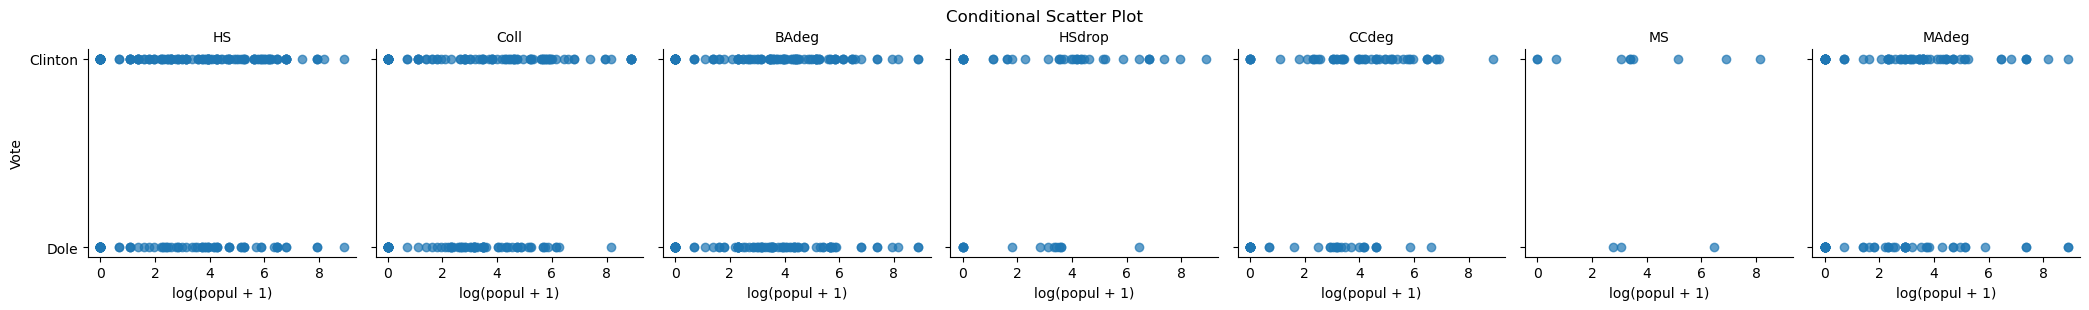

In [20]:
# Create conditional scatter plots

g = sns.FacetGrid(nes96, col="educ", height=3, aspect=1)
g.map(plt.scatter, "log_popul", "vote", alpha=0.7) # vote_encoded for binary y

# Set axis labels and titles
g.set_axis_labels("log(popul + 1)", "Vote")
g.set_titles(col_template="{col_name}")

# Add a main title
g.fig.suptitle("Conditional Scatter Plot", y=1.02)

plt.show()

### 2.2    Analyse data for this interaction
Test the hypothesis, that the effect of population density depends on a voter’s educational status. To do so, fit the GLM and then summarise the finding in two ways: (1) using anova_lm(fit, typ=2 or 3) and (2) using fit.summary() <br>

Do they tell the same story?

In [22]:
# model 1: CAUTION> this is NOT the right way for the ANOVA because Fitting ols is assuming Normal response when it is actually Binary

formula = 'vote_encoded ~ np.log(popul + 1) * educ'
fint1 = ols(formula, data=nes96).fit()

# perform ANOVA
anova_result = anova_lm(fint1, typ=2)

print(anova_result)

                            sum_sq     df          F        PR(>F)
educ                      2.786701    6.0   1.977980  6.615182e-02
np.log(popul + 1)         6.565773    1.0  27.962020  1.542671e-07
np.log(popul + 1):educ    1.709044    6.0   1.213067  2.969783e-01
Residual                218.373684  930.0        NaN           NaN


In [23]:
# model 2: 
formula = 'vote_encoded ~ np.log(popul + 1) * educ'

# Fit logistic regression model
fint = sm.GLM.from_formula(formula, data=nes96, family=sm.families.Binomial()).fit()

print(fint.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:           vote_encoded   No. Observations:                  944
Model:                            GLM   Df Residuals:                      930
Model Family:                Binomial   Df Model:                           13
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -617.29
Date:                Tue, 28 Oct 2025   Deviance:                       1234.6
Time:                        13:16:07   Pearson chi2:                     941.
No. Iterations:                     4   Pseudo R-squ. (CS):            0.04908
Covariance Type:            nonrobust                                         
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercep

In [24]:
# another way

from statsmodels.formula.api import glm

formula = 'vote_encoded ~ np.log(popul + 1) * educ'

# Fit logistic regression model
fint3 = glm(formula, data=nes96, family=sm.families.Binomial()).fit()

print(fint3.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           vote_encoded   No. Observations:                  944
Model:                            GLM   Df Residuals:                      930
Model Family:                Binomial   Df Model:                           13
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -617.29
Date:                Tue, 28 Oct 2025   Deviance:                       1234.6
Time:                        13:16:41   Pearson chi2:                     941.
No. Iterations:                     4   Pseudo R-squ. (CS):            0.04908
Covariance Type:            nonrobust                                         
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercep

In [25]:
# Fit the educ on vote(Dole=1) to manualy calculate the values for the ANOVA (for curiocity sake)

feduc = sm.GLM.from_formula(formula='vote_encoded ~ educ', data=nes96, family=sm.families.Binomial()).fit()

dev_log =  fm2.null_deviance - fm2.deviance
dev_edu = feduc.null_deviance - feduc.deviance
dev_int = fint.null_deviance - fint.deviance - dev_log - dev_edu
df_int = fint.df_model - 1 - feduc.df_model
res_df_null = fm2.df_resid + fm2.df_model
res_df_edu = fint.df_resid + df_int
res_dev_edu = fint.deviance + dev_int

p_value_log = 1 - stats.chi2.cdf(fm2.deviance, fm2.df_resid)
p_value_edu = 1 - stats.chi2.cdf(dev_edu, fm2.df_resid - res_df_edu)
p_value_int = 1 - stats.chi2.cdf(dev_int, fm2.df_resid - fint.df_resid)


print("ANOVA")
table = [["Term", "Df", "Deviance", "Resid. Df", "Resid Dev.", "Pr(>Chi)"],
         ["NULL", "", "",  res_df_null, fint.null_deviance,  ""],
         ["log(popul + 1)", fm2.df_model, round(dev_log, 3), fm2.df_resid, fm2.deviance, round(p_value_log,5)],
         ["educ", feduc.df_model, round(dev_edu, 3), res_df_edu, res_dev_edu, round(p_value_edu,5)],
         ["log(popul + 1):educ", df_int, round(dev_int, 3), fint.df_resid, fint.deviance, round(p_value_int,5)]]

print(tabulate(table, headers="firstrow"))

ANOVA
Term                 Df    Deviance      Resid. Df    Resid Dev.  Pr(>Chi)
-------------------  ----  ----------  -----------  ------------  ----------
NULL                                           943       1282.09
log(popul + 1)       1     27.284              942       1254.81  0.0
educ                 6     11.633              936       1243.18  0.07067
log(popul + 1):educ  6     8.585               930       1234.59  0.73787



### 2.3   Plot the GLM effects
Because it will become rather messy with so many error lines, in this very exceptional case, only plot the effect of population density for each educational level without confidence interval.

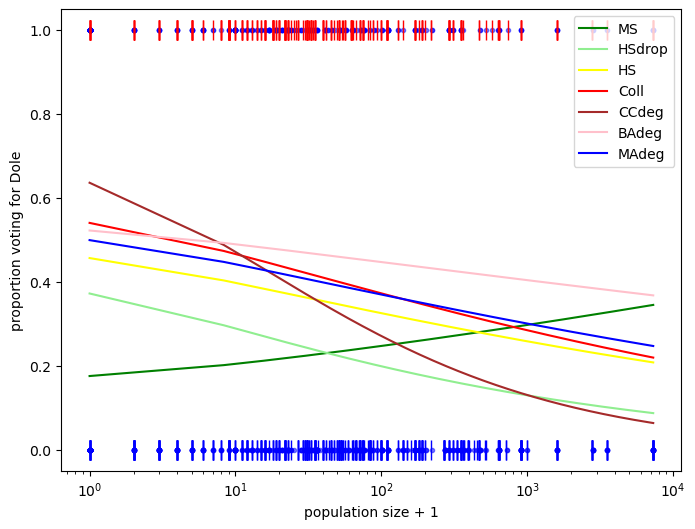

In [26]:
Pop = np.linspace(0, 7300, num=1001) + 1
newPop = [round(num, 1) for num in Pop] # rounding to 1 decimal place

# Predict probabilities for each education level
educ_levels = ["MS", "HSdrop", "HS", "Coll", "CCdeg", "BAdeg", "MAdeg"]
preds = {}
for educ_level in educ_levels:
    d = {'popul': newPop, 'educ':educ_level}
    new_df = pd.DataFrame(data=d)     # Convert to a dataframe
    preds[educ_level] = fint.get_prediction(new_df).summary_frame(alpha=0.05) # response-type predictions

popul = nes96['popul'] + 1
Dole = nes96['Dole']

# Create a scatter plot with log-scaled x-axis
plt.figure(figsize=(8, 6))
plt.scatter(popul, Dole, c='blue', marker='.', alpha=0.5)

# Create a rug plot
x1 = nes96.loc[nes96['Dole'] == 1, 'popul']
x2 = nes96.loc[nes96['Dole'] == 0, 'popul']

plt.plot(x1, np.ones_like(x1), '|', color='red', markersize=15) #top
plt.plot(x2, np.zeros_like(x2), '|', color='blue', markersize=15) #bottom
plt.xscale('log')

# add the lines
plt.plot(newPop, preds['MS']['mean'], label='MS', color='green')
plt.plot(newPop, preds['HSdrop']['mean'], label='HSdrop', color='lightgreen')
plt.plot(newPop, preds['HS']['mean'], label='HS', color='yellow')
plt.plot(newPop, preds['Coll']['mean'], label='Coll', color='red')
plt.plot(newPop, preds['CCdeg']['mean'], label='CCdeg', color='brown')
plt.plot(newPop, preds['BAdeg']['mean'], label='BAdeg', color='pink')
plt.plot(newPop, preds['MAdeg']['mean'], label='MAdeg', color='blue')

plt.xlabel('population size + 1')
plt.ylabel('proportion voting for Dole')
plt.legend(loc='upper right')

plt.show()


Note that it is difficult to align the output of the summary with the lines: which one represents the significant interaction? <br> 

And, yes, for production purposes we should really add confidence intervals to each line (which makes it a bit messy
to look at).